In [1]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langgraph.graph.message import add_messages
from typing import Annotated, TypedDict
from pathlib import Path
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool

load_dotenv()

C:\Users\ansha\AppData\Local\Temp\ipykernel_4188\2710225745.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


True

In [ ]:
llm=ChatGroq(model="openai/gpt-oss-120b")
# llm.invoke('hello').content

'Hello! How can I assist you today?'

In [6]:

class SubState(TypedDict):

    input_text: str
    translated_text: str

In [7]:
def translate_text(state:SubState):
    prompt = f"""
    Translate the following text to Hindi.
    Keep it natural and clear. Do not add extra content.

    Text:
    {state["input_text"]}
    """.strip()
    translated_text = llm.invoke(prompt).content

    return {'translated_text': translated_text}

     


In [8]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [9]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [10]:
def generate_answer(state: ParentState):

    answer = llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [11]:
def translate_answer(state: ParentState):

    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [12]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

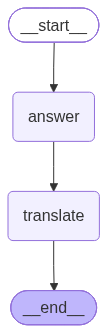

In [13]:
graph = parent_builder.compile()

graph

In [14]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': '**Quantum physics** (also called quantum mechanics or quantum theory) is the branch of physics that describes how nature behaves at the smallest scales—typically at the level of atoms, electrons, photons, and other elementary particles.  \n\n---\n\n## Why classical physics isn’t enough\n- **Classical physics** (Newtonian mechanics, electromagnetism, thermodynamics) works extremely well for everyday objects—cars, planets, bridges, etc.\n- When we probe phenomena at distances comparable to the size of atoms (≈10⁻¹⁰\u202fm) or at energies of a few electron‑volts, classical equations predict results that are **systematically wrong**.\n- Experiments such as the photoelectric effect, black‑body radiation, atomic spectra, and electron diffraction revealed behavior that could not be explained without a new framework—quantum physics.\n\n---\n\n## Core Principles\n\n| Principle | What it says | Everyday analogy (imperfect) |\n|-----------|-